## [LAB-07] 추론통계

### 04-3_이원분산분석

### #01 준비작업

#### 1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *
import numpy as np
from pandas import DataFrame

# 시각화 라이브러리
import seaborn as sb

# 분산분석을 위한 라이브러리
from pingouin import anova
from statsmodels.formula.api import ols
from statsmodels import api as sm

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


#### 2. 데이터 가져오기

- 식물의 성장이 햇빛 노출과 관수 빈도에 의해 영향을 받는지 여부를 알기 위해 씨앗을 심고 햇빛 노출과 물 주기를 다른 조건으로 하여 두 달 동안 자라게 한 후 각 식물의 높이를 인치 단위로 기록한 데이터

In [2]:
origin = load_data('sunlight_watering_growth')
origin.head()

📚 식물의 씨앗을 심고 햇빛 노출과 물 주기를 다른 조건으로 하여 두 달 동안 자라게 한 후 각 식물의 높이를 인치 단위로 기록한 데이터 (출처: 방송통신대학교 통계학개론)


,water,sun,height
0,daily,low,4.900
1,daily,low,7.900
2,daily,low,3.900
3,daily,low,5.100
4,daily,low,5.200


### #02 데이터 분포 확인

#### 1. 관수빈도에 따른 햇빛 노출량별 식물 높이 비교

In [3]:
# 필요한 변수 정의
field = 'height'        # 연속형 컬럼명
group_field = 'water'   # 명목형 컬럼명 1 (~~에 따른)
hue_field = 'sun'       # 명목형 컬럼명 2 (~~별)

# 그룹별 값의 종류 확인
group_values = origin[group_field].unique()
print(f'그룹별 값의 종류: {group_values}')

# 시각화 할 필드만 원본 데이터에서 추출
data = origin[[field, group_field, hue_field]]
data.head()

그룹별 값의 종류: <ArrowStringArray>
['daily', 'weekly']
Length: 2, dtype: str


,height,water,sun
0,4.900,daily,low
1,7.900,daily,low
2,3.900,daily,low
3,5.100,daily,low
4,5.200,daily,low


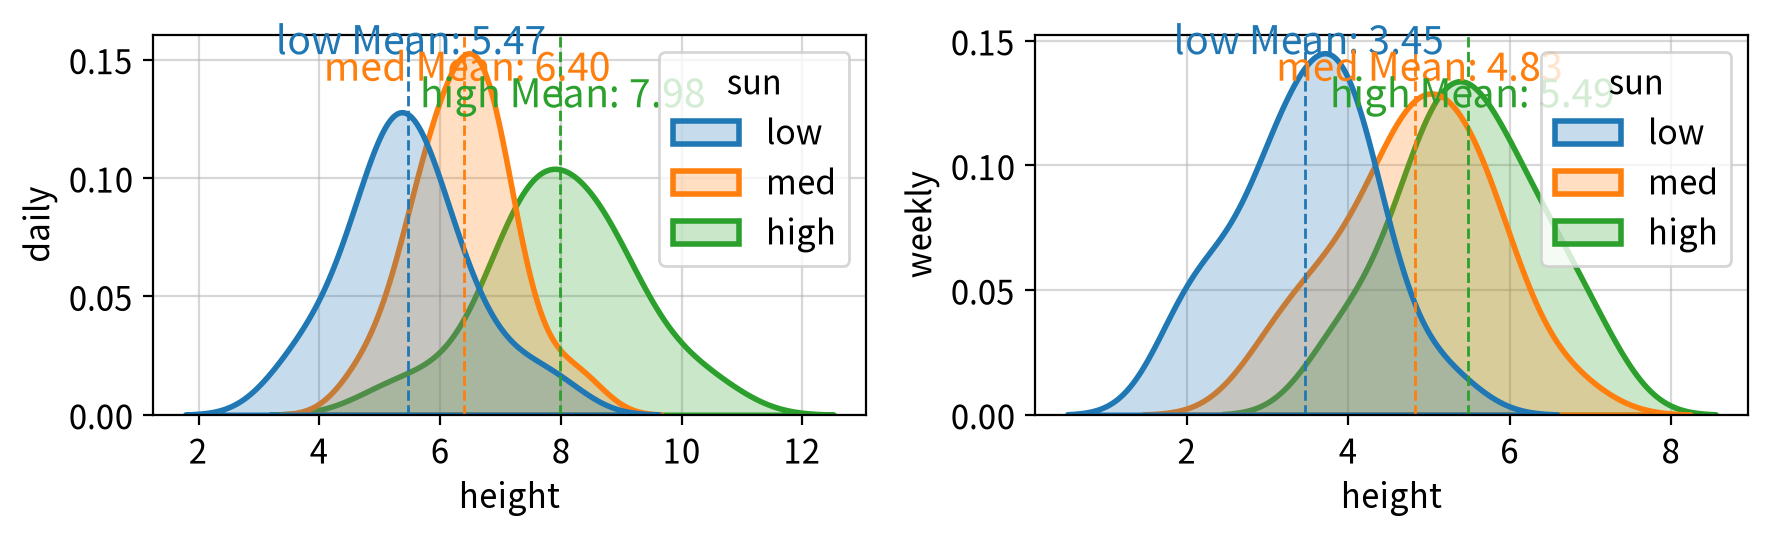

In [4]:
fig, ax = my_plot.init(cols=len(group_values), width=900, height=300)

for i, v in enumerate(group_values):
    temp = data[data[group_field] == v]

    my_plot.kdeplot(data=temp, x=field, hue=hue_field, fill=True, meanline=True, ax=ax[i])
    ax[i].set_ylabel(v)

my_plot.show()

> 매일(daily) 물을 준 식물과 일주일에 한 번(weekly) 물을 준 식물 모두 햇빛을 더 많이 받은 경우의 성장 분포가 더 오른쪽에 있다. -> 더 잘 자랐다.

#### 2. 햇빛 노출량에 따른 관수빈도별 식물 높이 비교

In [5]:
# 필요한 변수 정의
field = 'height'        # 연속형 컬럼명
group_field = 'sun'     # 명목형 컬럼명 1 (~~에 따른)
hue_field = 'water'     # 명목형 컬럼명 2 (~~별)

# 그룹별 값의 종류 확인
group_values = origin[group_field].unique()
print(f'그룹별 값의 종류: {group_values}')

# 시각화 할 필드만 원본 데이터에서 추출
data = origin[[field, group_field, hue_field]]
data.head()

그룹별 값의 종류: <ArrowStringArray>
['low', 'med', 'high']
Length: 3, dtype: str


,height,sun,water
0,4.900,low,daily
1,7.900,low,daily
2,3.900,low,daily
3,5.100,low,daily
4,5.200,low,daily


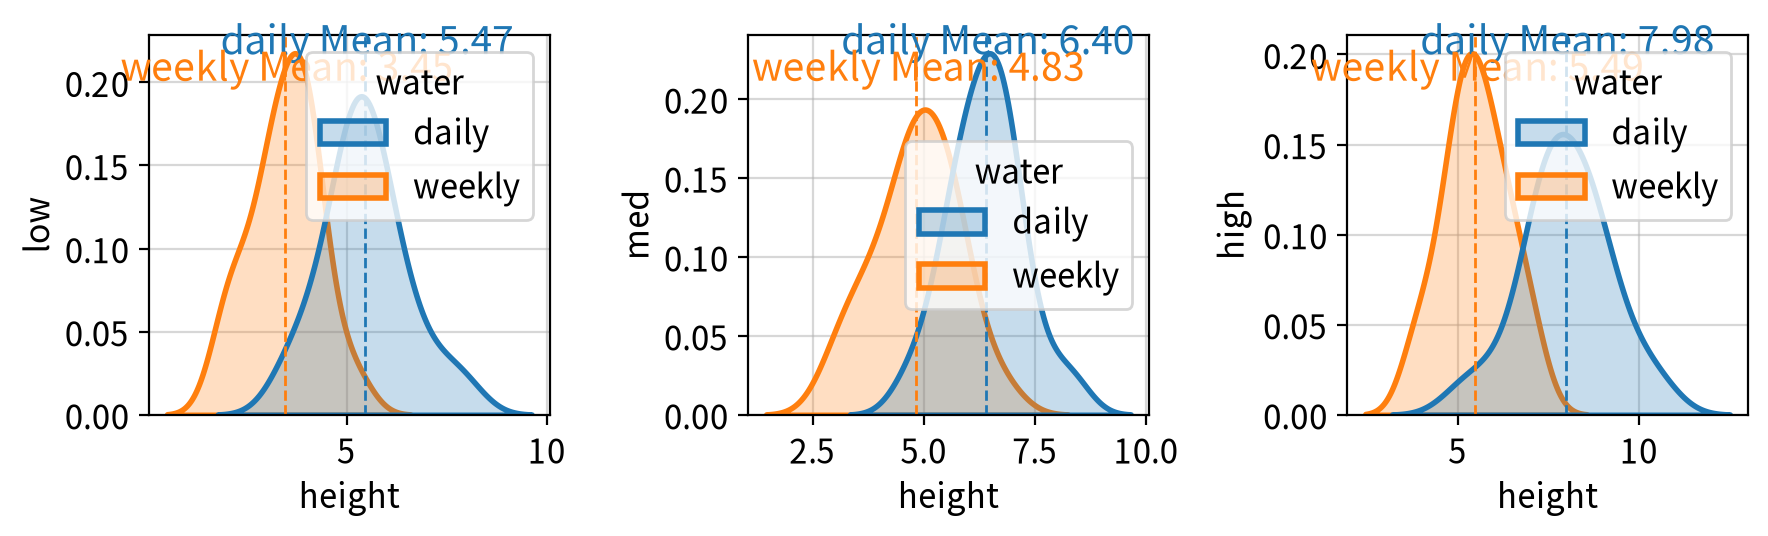

In [6]:
fig, ax = my_plot.init(cols=len(group_values), width=900, height=300)

for i, v in enumerate(group_values):
    temp = data[data[group_field] == v]

    my_plot.kdeplot(data=temp, x=field, hue=hue_field, fill=True, meanline=True, ax=ax[i])
    ax[i].set_ylabel(v)

my_plot.show()

> 햇빛 노출 빈도에 상관 없이 물을 매일 준 식물이 더 잘 자란다.

### #03 분산분석의 가정 확인

#### 1. 모든 명목형의 조합에 따른 종속변수 재배치

In [7]:
data = origin.copy()
xname = ['water', 'sun']        # 명목형 변수의 이름
yname = 'height'                # 연속형 변수의 이름

# 두 명목형 변수의 모든 조합별로 연속형 변수 값을 별도의 컬럼으로 분리한다.
groups = {}
for i in data[xname[0]].unique():
    for j in data[xname[1]].unique():
        # 명목형 변수의 조합 조건에 맞는 데이터를 추출한다.
        filtered_data = data[(data[xname[0]] == i) & (data[xname[1]] == j)][yname]
        groups["{0}, {1}".format(i, j)] = filtered_data.reset_index(drop=True)

# 조합별 표본 크기가 다를 수 있으므로 DataFrame으로 결합하면 짧은 쪽은 NaN으로 채워진다.
# test_assumptions는 내부적으로 결측치를 제거한 뒤 검정하므로 문제되지 않는다.
group_df = DataFrame(groups)
group_df.head()

,"daily, low","daily, med","daily, high","weekly, low","weekly, med","weekly, high"
0,4.900,5.600,8.600,3.900,4.800,5.200
1,7.900,6.500,8.800,3.300,3.600,4.700
2,3.900,6.500,9.200,4.300,5.700,6.900
3,5.100,6.000,7.100,3.300,4.100,5.100
4,5.200,7.100,8.600,4.500,4.600,7.100


#### 2. 정규성에 따른 등분산성 검정

In [8]:
# 정규성(normaltest)과 등분산성(Bartlett/Levene) 가정을 일괄 검정한다.
rdf = my_stats.test_assumptions(group_df)
display(rdf)

# 등분산성 충족 여부 (이후 사후검정 방법 선택에 사용)
equal_var = bool(rdf.loc[rdf['test'] == 'equal_var', 'result'].iloc[0])
equal_var

,test,statistic,p-value,result
field,,,,
"daily, low",normaltest,1.462,0.482,True
"daily, med",normaltest,0.867,0.648,True
"daily, high",normaltest,0.802,0.670,True
"weekly, low",normaltest,0.074,0.964,True
"weekly, med",normaltest,0.161,0.923,True
"weekly, high",normaltest,0.053,0.974,True
Bartlett,equal_var,4.488,0.481,True


True

### #04 이원분산분석 수행

#### 1. 가정 충족 여부에 따른 이원분산분석

- 등분산성 충족 시: 일반적인 이원분산분석 수행
- 등분산성 미충족 시: 이원분산분석에는 Welch같은 적절한 대안이 없으므로, 등분산을 가정하지 않는 선형모형 기반의 Type-II ANOVA로 전환

In [9]:
# 분석 변수 정의
data = origin.copy()
xname = ['water', 'sun']        # 명목형(독립) 변수
yname = 'height'                # 연속형(종속) 변수

# 등분산성 가정(equal_var) 충족 여부에 따라 분석 방법 분기
if equal_var:
    # [등분산성 충족] 일반 이원분산분석
    aov = anova(data=data, dv=yname, between=xname).round(4)
    aov.insert(0, 'test', 'two-way ANOVA')
    # 유의성 판정 컬럼 추가 (p < 0.05 이면 효과 존재)
    aov['significant'] = aov['p_unc'] < 0.05

    # 효과크기(np2, partial eta-squared) 해석 (>=0.14 큼 / >=0.06 중간 / >=0.01 작음)
    conditions = [aov['np2'] >= 0.14,
                  aov['np2'] >= 0.06,
                  aov['np2'] >= 0.01]
    aov['effect_size'] = np.select(conditions, ["Large", "Medium", "Small"], default='Negligible')

else:
    # [등분산 미충족] 등분산을 가정하지 않는 선형모형(HC3) 기반 Type-II ANOVA
    model = ols(f'{yname} ~ C({xname[0]}) * C({xname[1]})', data=data)
    fit = model.fit(cov_type='HC3')
    aov = sm.stats.anova_lm(fit, typ=2, robust='hc3').round(4)
    aov.insert(0, 'test', 'OLS (HC3) Type-II ANOVA')
    # 유의성 판정 컬럼 추가 (p < 0.05 이면 효과 존재)
    # -> p-value 컬럼명이 'PR(>F)'로 되어있으므로 해당 컬럼명을 사용
    aov['significant'] = aov['PR(>F)'] < 0.05

aov

,test,Source,SS,DF,MS,F,p_unc,np2,significant,effect_size
0,two-way ANOVA,water,122.816,1,122.816,130.529,0.000,0.534,True,Large
1,two-way ANOVA,sun,103.292,2,51.646,54.889,0.000,0.491,True,Large
2,two-way ANOVA,water * sun,4.327,2,2.164,2.300,0.105,0.039,False,Small
3,two-way ANOVA,Residual,107.264,114,0.941,NaN,NaN,NaN,False,Negligible


> - **관수 빈도(water) 주효과는 유의하다** (p < 0.001).   
>   - 효과크기(np2=0.534)가 매우 커서, 매일 물을 준 식물(daily)이 주 1회 물을 준 식물(weekly)보다 분명하게 더 크게 자랐다.   
> - **햇빛 노출(sun) 주효과도 유의하다** (p < 0.001, np2=0.491).   
>   - 햇빛 노출량이 많을수록(high > med > low) 식물이 더 크게 자랐다.   
> - **상호작용효과(water × sun)는 유의하지 않다** (p = 0.105 > 0.05).   
>   - 효과크기 라벨은 Small(np2=0.039)이지만 통계적으로 유의하지 않으므로, 관수 빈도가 미치는 효과의 크기가 햇빛 노출 수준에 따라 크게 달라지지 않는다고 본다.   
> - 즉 두 요인은 서로 독립적으로 식물 성장에 기여한다.

### #05 이원분산분석 시각화

#### 1. 햇빛 노출량에 따른 관수 빈도별 평균 식물 높이

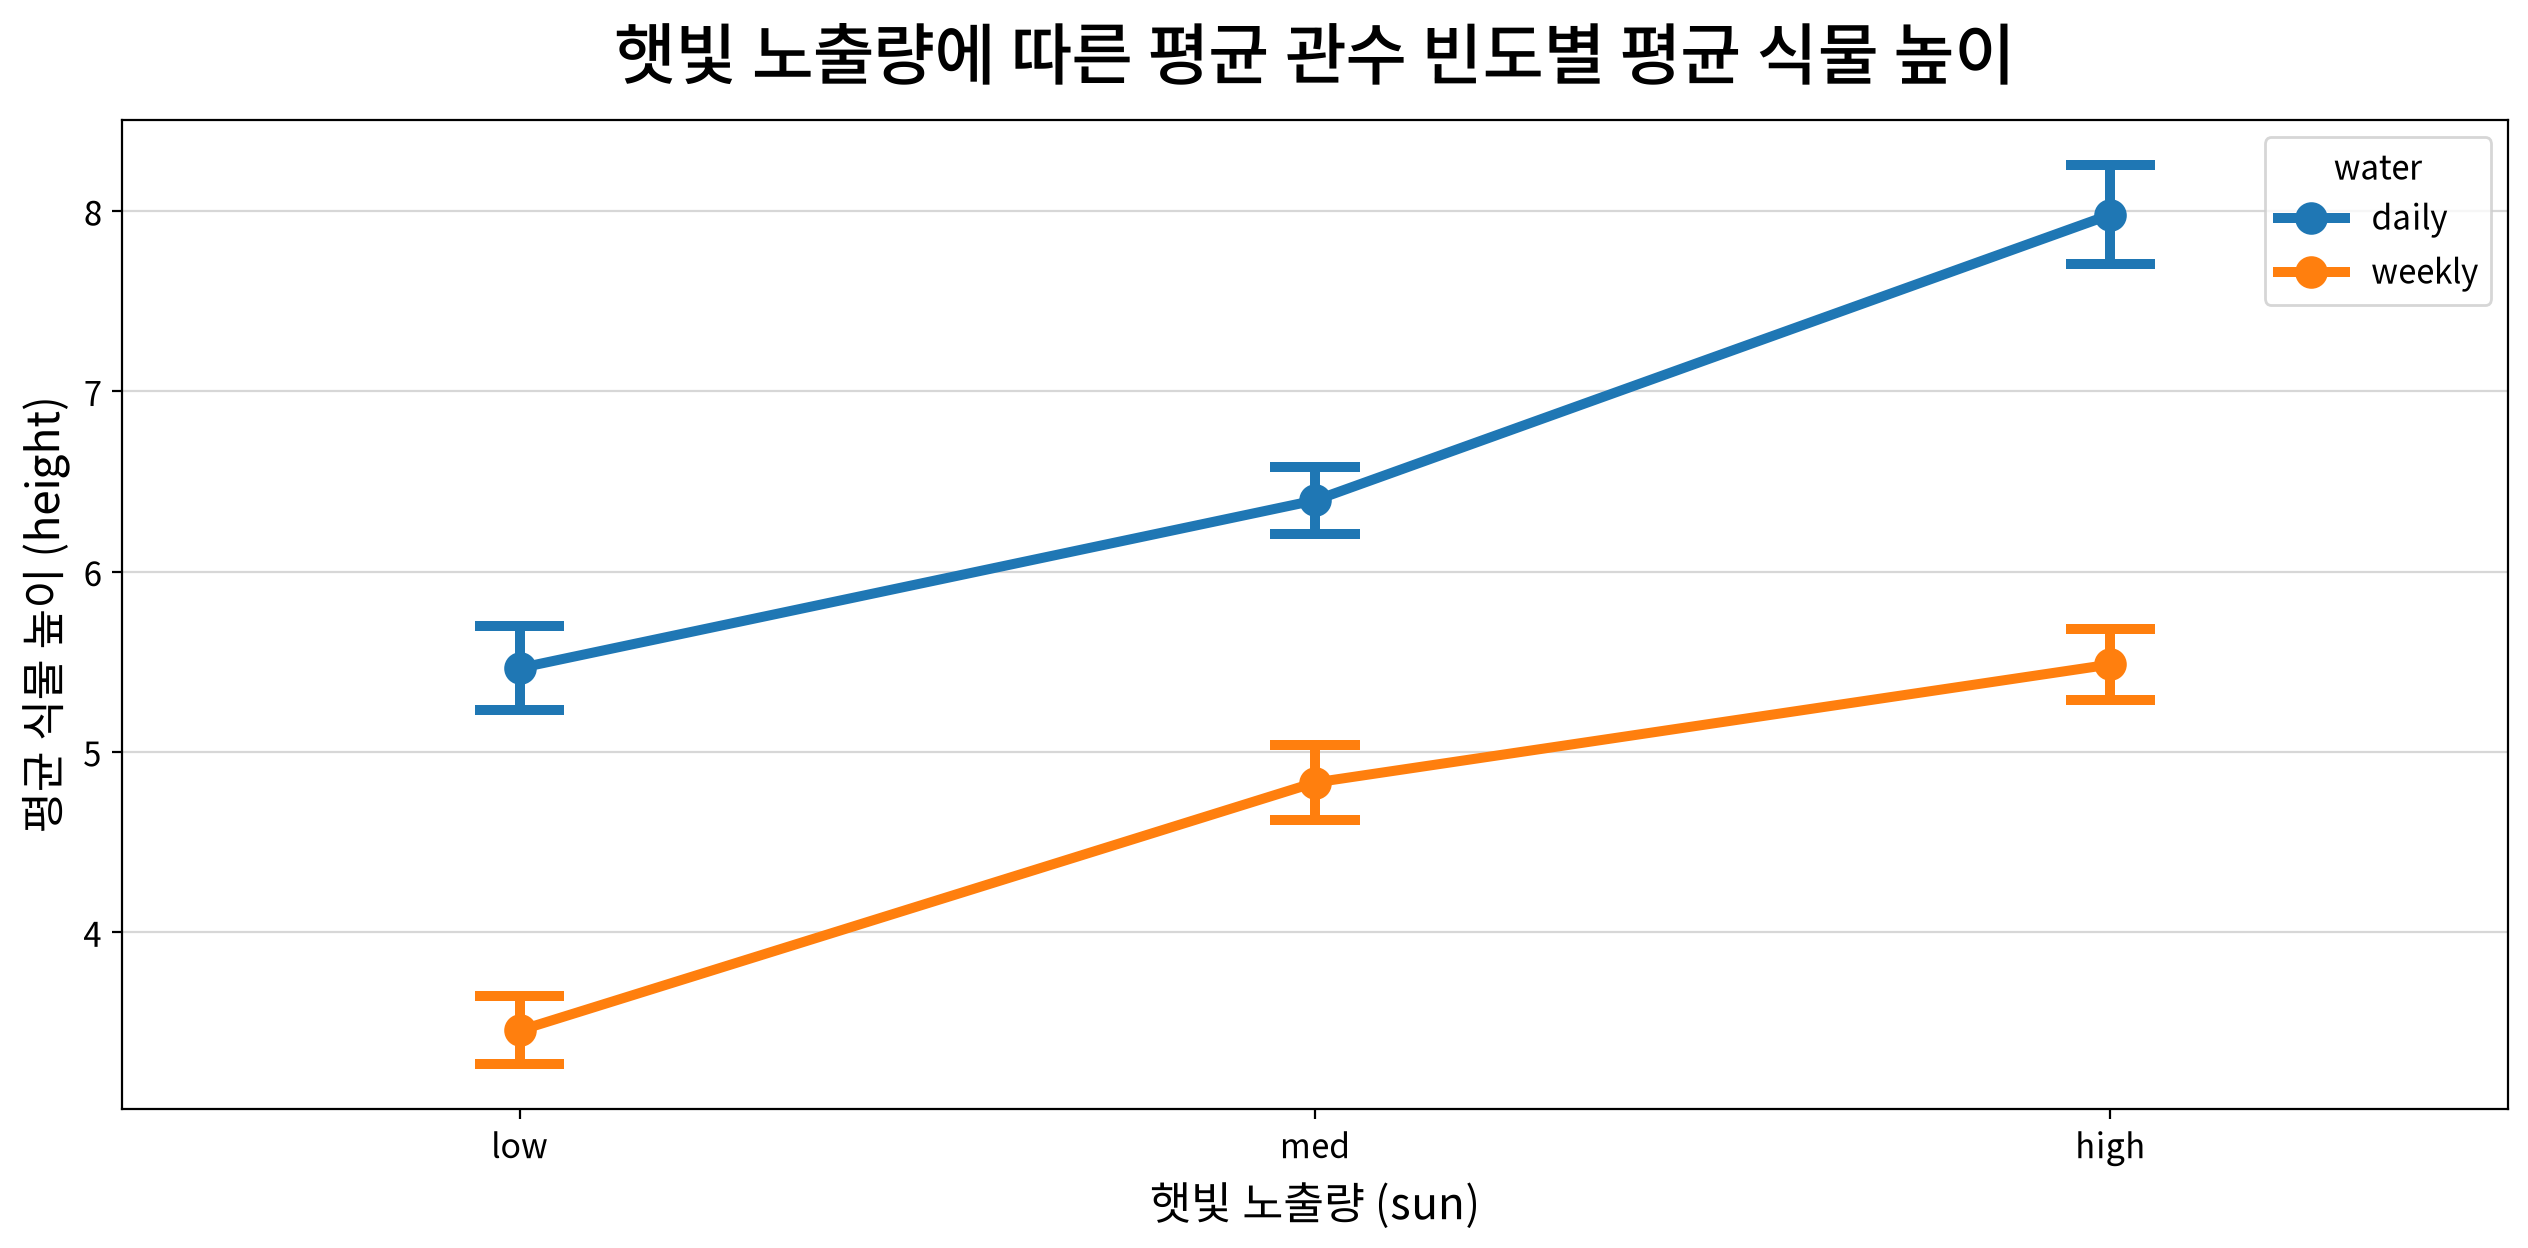

In [10]:
# 햇빛 노출량을 적은 > 많은 순으로 정렬
sun_order = ['low', 'med', 'high']

# 상호작용 플롯 - 햇빛 노출량(x축)에 따른 평균 식물 높이를 관수 빈도(선)별로 비교한다.
fig, ax = my_plot.init(title='햇빛 노출량에 따른 평균 관수 빈도별 평균 식물 높이',
                       xlabel='햇빛 노출량 (sun)', ylabel='평균 식물 높이 (height)')

# errorbar='se' --> 표준오차(standard error)를 계산하여 오차막대(errorbar) 표시
# capsize=0.1 --> 오차막대 끝에 수평선 표시 (순전히 가독성용이라 통계적 의미 없음)
sb.pointplot(data=origin, x='sun', y='height', hue='water',
             errorbar='se', capsize=0.1, order=sun_order, ax=ax)

my_plot.show()

> - **햇빛(sun) 주효과:** 두 선이 모두 우상향(low → med → high) → 햇빛 노출량이 많을수록 식물이 크게 자람
> - **관수 빈도(water) 주효과:** daily 선이 weekly 선보다 항상 위에 위치 → 매일 물을 준 쪽이 더 크게 자람
> - **상호작용효과(water × sun):** 두 선이 교차하지 않고 거의 평행 → 상호작용은 미미(p ≥ 0.05)

#### 2. 관수 빈도에 따른 햇빛 노출량별 평균 식물 높이

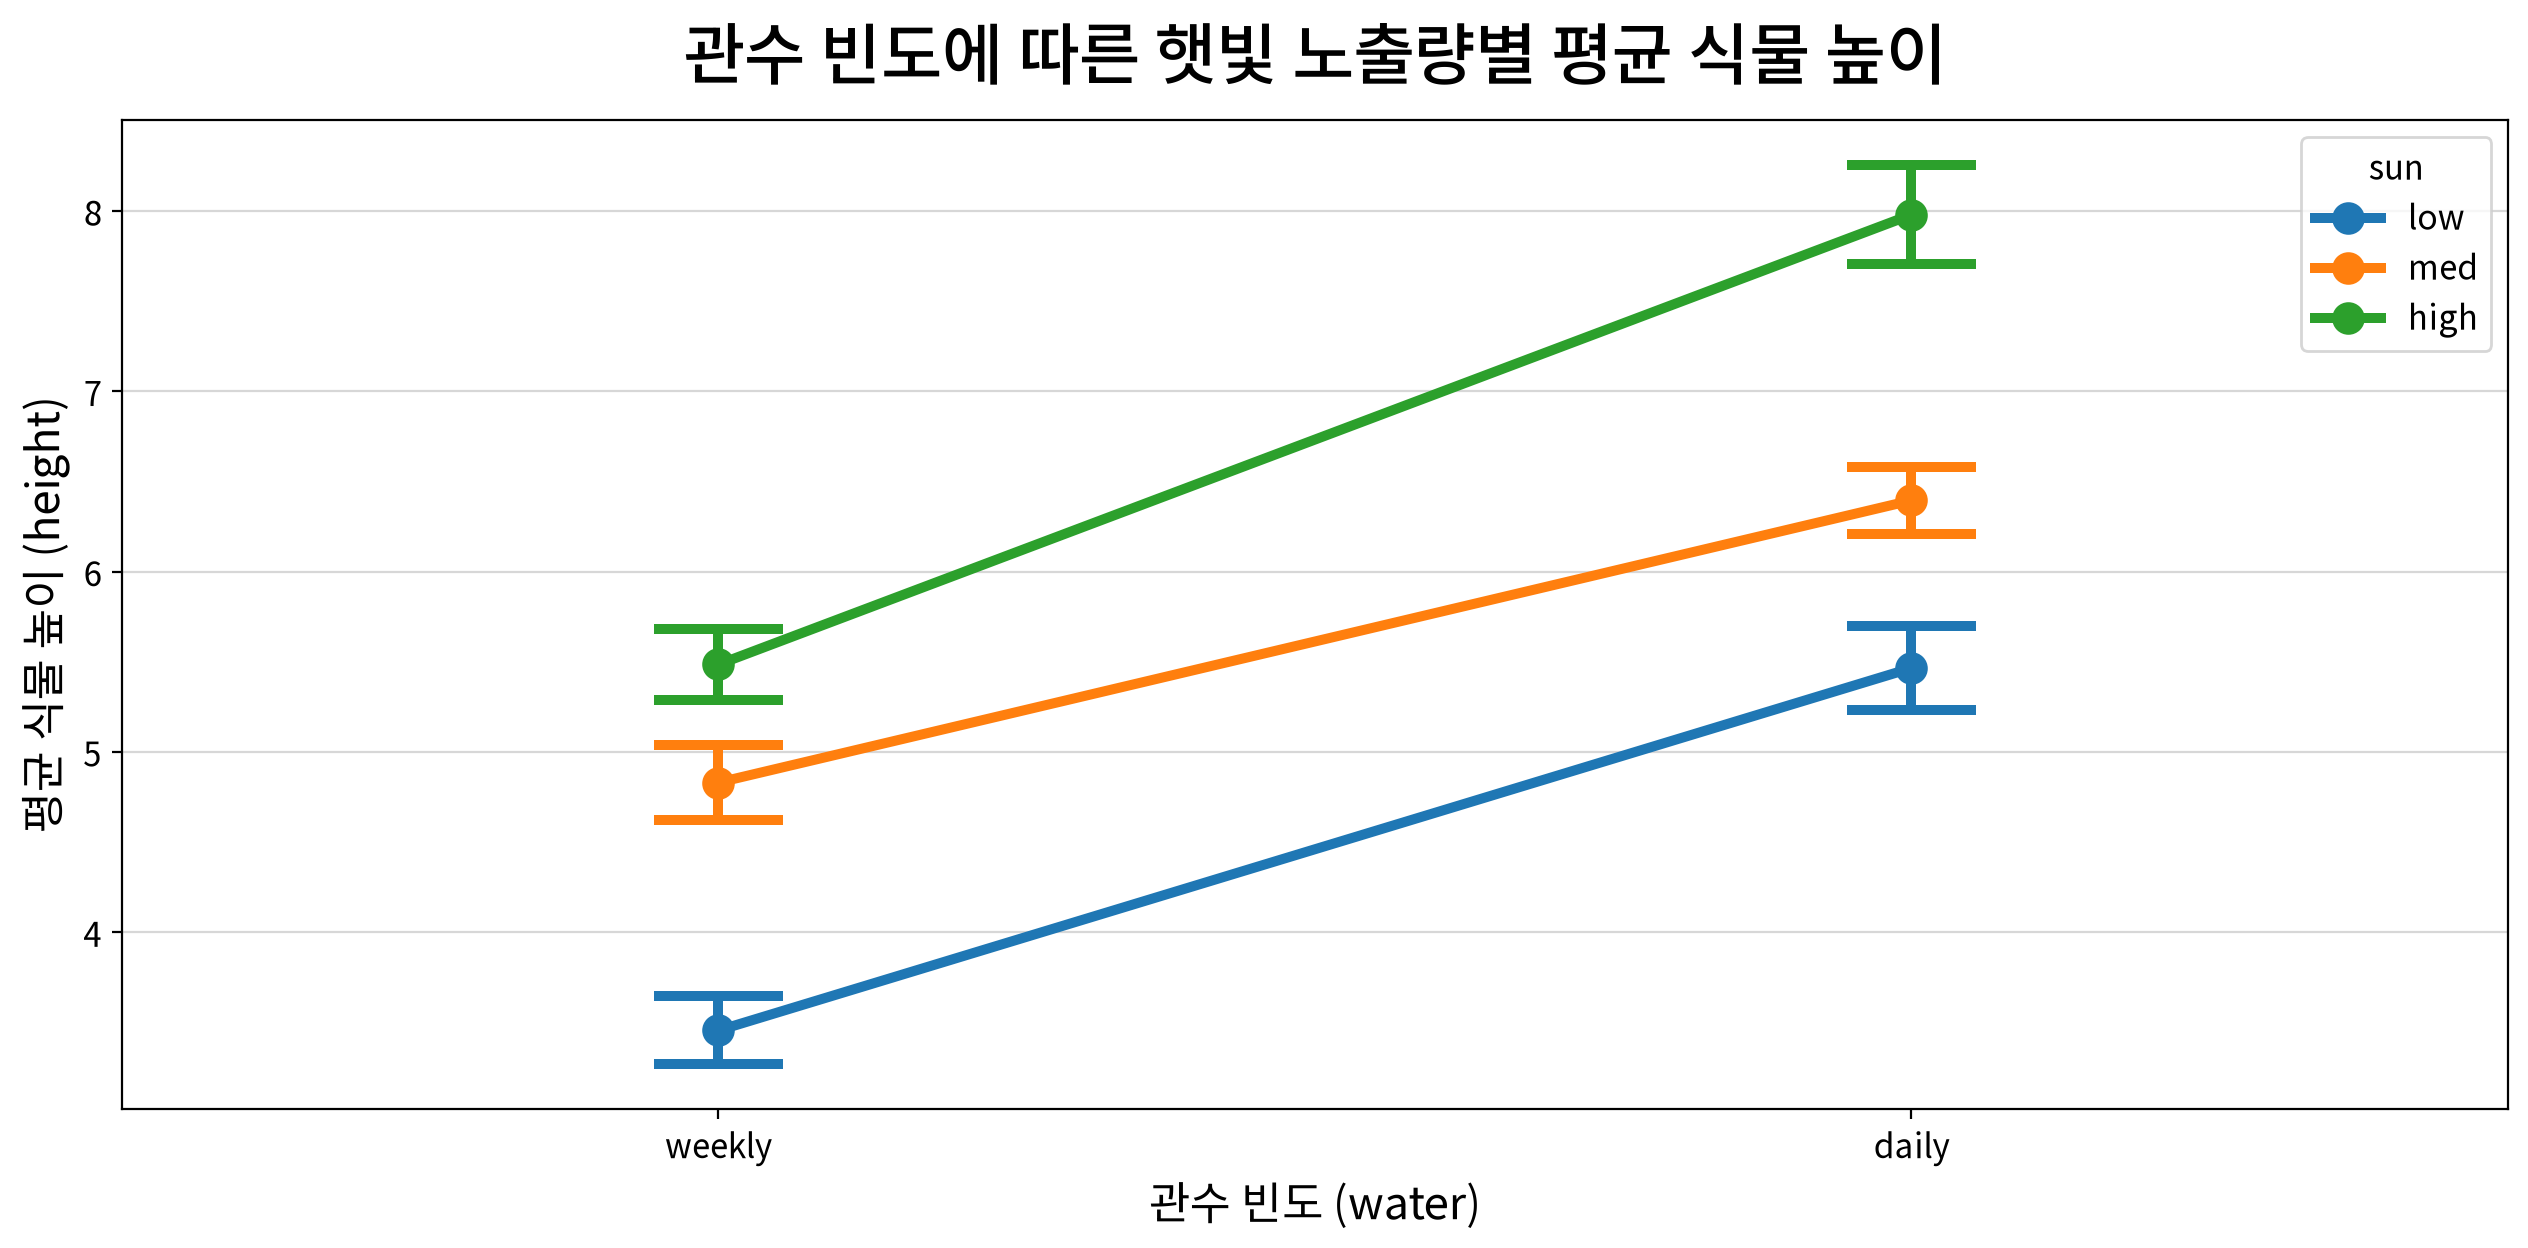

In [11]:
# 관수 빈도를 적은 > 많은 순으로 정렬
water_order = ['weekly', 'daily']

# 상호작용 플롯 - 햇빛 노출량(x축)에 따른 평균 식물 높이를 관수 빈도(선)별로 비교한다.
fig, ax = my_plot.init(title='관수 빈도에 따른 햇빛 노출량별 평균 식물 높이',
                       xlabel='관수 빈도 (water)', ylabel='평균 식물 높이 (height)')

# errorbar='se' --> 표준오차(standard error)를 계산하여 오차막대(errorbar) 표시
# capsize=0.1 --> 오차막대 끝에 수평선 표시 (순전히 가독성용이라 통계적 의미 없음)
sb.pointplot(data=origin, x='water', y='height', hue='sun',
             errorbar='se', capsize=0.1, order=water_order, ax=ax)

my_plot.show()

> - **관수 빈도(water) 주효과:** 세 선이 모두 weekly → daily로 우상향 → 매일 물을 준 쪽이 더 크게 자람
> - **햇빛(sun) 주효과:** high > med > low 순으로 위에서부터 층층이 쌓여 있음 → 햇빛 노출량이 많을수록 식물이 크게 자람
> - **상호작용효과(water × sun):** 세 선이 교차하지 않고 거의 평행 → 상호작용은 미미(p ≥ 0.05)

### #06 모듈화 기능 확인

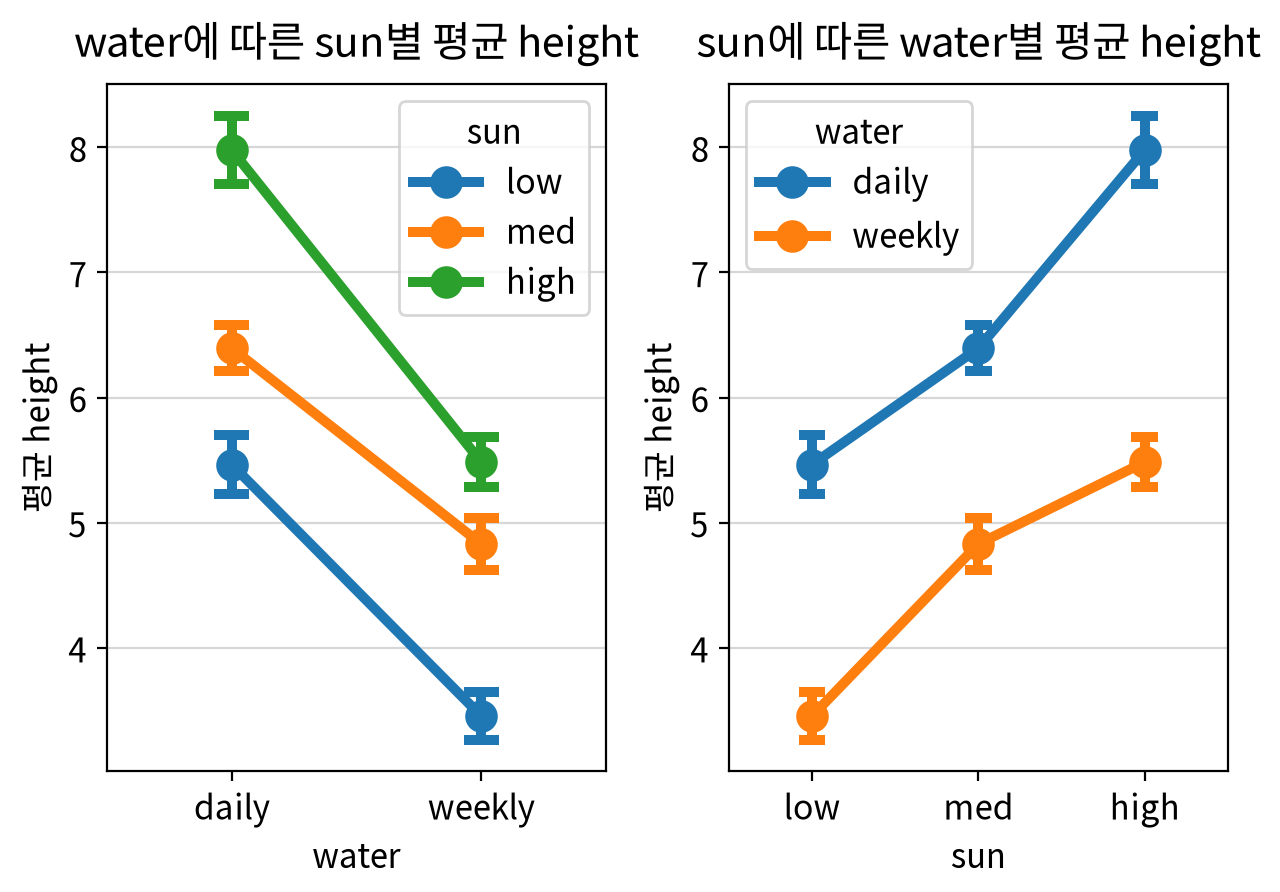

,test,Source,SS,DF,MS,F,p_unc,np2,significant,effect_size
0,two-way ANOVA,water,122.816,1,122.816,130.529,0.000,0.534,True,Large
1,two-way ANOVA,sun,103.292,2,51.646,54.889,0.000,0.491,True,Large
2,two-way ANOVA,water * sun,4.327,2,2.164,2.299,0.105,0.039,False,Small
3,two-way ANOVA,Residual,107.264,114,0.941,NaN,NaN,NaN,False,-


In [13]:
my_stats.anova_twoway(origin, y='height', between=['water', 'sun'])

---

## 연습문제

#### 문제 1: 신입교사의 교육방법 채택 고민
- 당신은 한울고등학교의 연구교사로 부임했습니다.
    - 지난 학기 학생 22명을 11명씩 나눠 두 가지 교육방법으로 가르친 뒤 국어·영어 시험을 치렀고 그 결과를 `edu` 데이터 셋으로 저장해 두었습니다.
    - 이 데이터를 근거로 2번 교육 방법으로 바꾸려고 하는데, 어떤 선생님은 영어에서만 통한다고 합니다.
    - 교육 방법과 과목, 두 요인이 각각 그리고 맞물려서 점수에 영향을 주는지 확인하세요.

- **문제**
    - '과목'을 하나의 요인으로 다루려면 점수를 한 열에 모은 형태로 데이터를 재배치해야 합니다. 재배치된 데이터의 관측치(행) 개수는 몇 개 인가요?
    - 두 요인과 그 맞물림까지 한 번에 검정한 결과표의 세 효과 중, 검정통계량 값이 가장 큰 효과는 무엇인가요?
    - "2번 방법이 영어에서만 통한다"가 사실이라면 두 요인의 맞물림 효과가 드러나야 합니다. 이 효과의 유의확률(p-value)은 얼마인가요?
    - 유의수준 5% 기준으로, 세 효과 중 유의하다고 판정되는 효과의 개수는 몇 개 인가요?
    - 당신이 교육 방법의 변경을 주장하려면 2번 교육방법의 효과를 입증해야 합니다. 2번 교육 효과의 효과크기는 결과표에서 어떤 등급으로 판정되었나요?

In [17]:
# 라이브러리 불러오기
from pandas import melt

In [18]:
# 데이터 불러오기
df1 = load_data('edu')
df1.head()

📚 두 가지 교육방법을 비교하기 위하여 능력이 비슷한 고등학교 학생 22명을 추출하고, 11명씩 두 집단으로 나누어 한 학기 동안 각각의 교육방법으로 교육시킨 후 치른 학기말 시험 성적을 조사한 자료 (출처: 방송통신대학교 통계학 개론)


,교육방법,국어,영어
0,1,65,82
1,1,87,79
2,1,73,85
3,1,79,60
4,1,81,65


In [30]:
# 데이터 재배치
mdf1 = melt(df1, id_vars=['교육방법'], value_vars=['국어', '영어'],
            var_name='과목', value_name='점수')
display(len(mdf1))
mdf1.head()

44

,교육방법,과목,점수
0,1,국어,65
1,1,국어,87
2,1,국어,73
3,1,국어,79
4,1,국어,81


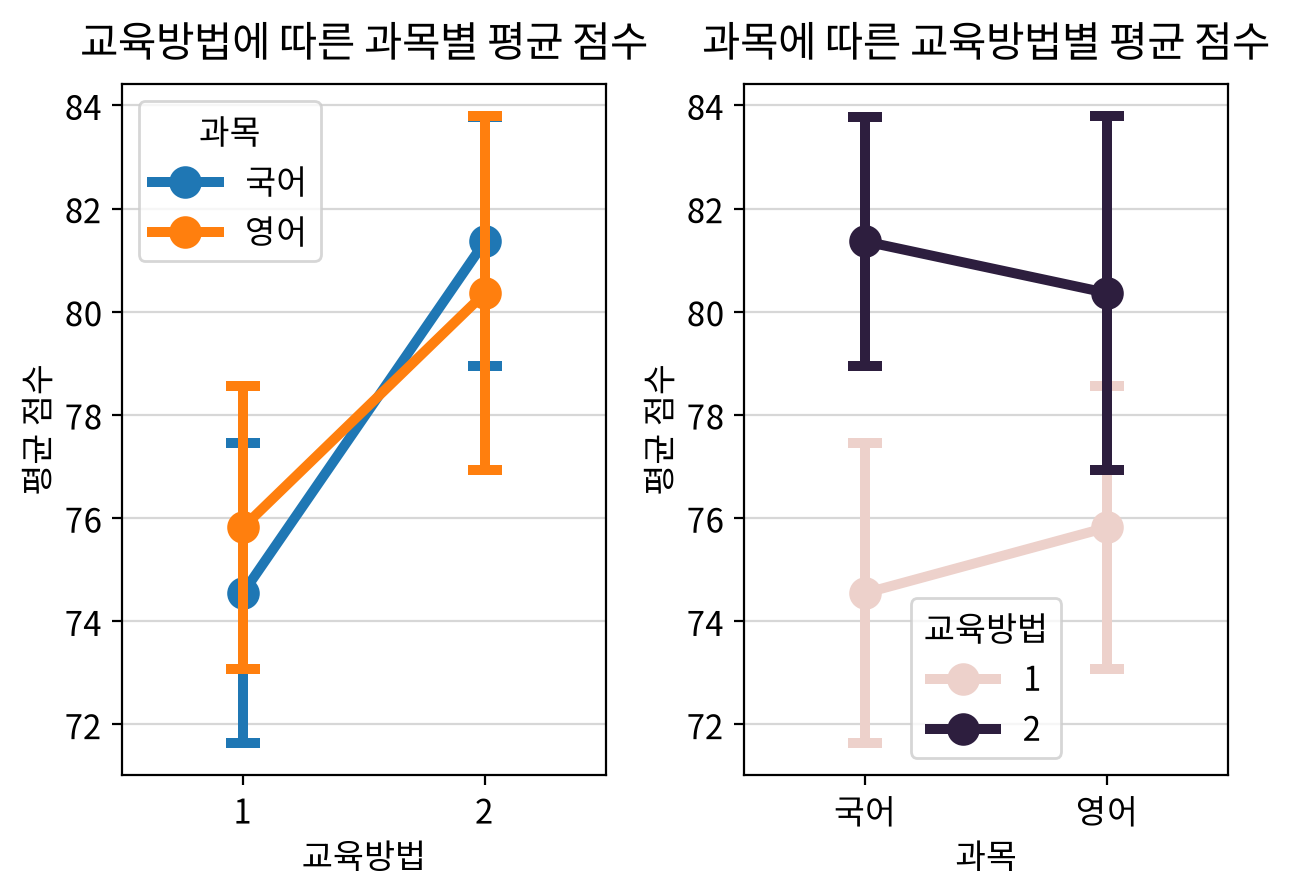

,test,Source,SS,DF,MS,F,p_unc,np2,significant,effect_size
0,two-way ANOVA,교육방법,355.114,1,355.114,3.846,0.057,0.088,False,Medium
1,two-way ANOVA,과목,0.205,1,0.205,0.002,0.963,0.000,False,Negligible
2,two-way ANOVA,교육방법 * 과목,14.205,1,14.205,0.154,0.697,0.004,False,Negligible
3,two-way ANOVA,Residual,3693.455,40,92.336,NaN,NaN,NaN,False,-


In [ ]:
my_stats.anova_twoway(mdf1, y='점수', between=['교육방법', '과목'], width=600)

- 교육방법의 주효과는 유의하지 않다 (p > 0.05).   
  - 효과크기(np2=0.088)는 중간 수준으로, 효과가 전혀 없다고 단정할 수는 없지만 현재 검정에서는 통계적 유의성을 확보하지 못했다.
- 과목의 주효과도 유의하지 않다 (p > 0.05, np2=0.000).    
- 상호작용효과(교육방법 * 과목)는 유의하지 않다 (p = 0.697 > 0.05).   
  - 통계적으로 유의하지 않으므로, 교육방법이 미치는 효과의 크기가 과목에 따라 크게 달라지지 않는다고 본다.   
- 즉 두 요인은 모두 점수에 영향 주지 않는다.

**답변**
- '과목'을 하나의 요인으로 다루려면 점수를 한 열에 모은 형태로 데이터를 재배치해야 합니다. 재배치된 데이터의 관측치(행) 개수는 몇 개 인가요?
    - 44개
- 두 요인과 그 맞물림까지 한 번에 검정한 결과표의 세 효과 중, 검정통계량 값이 가장 큰 효과는 무엇인가요?
    - 교육방법
- "2번 방법이 영어에서만 통한다"가 사실이라면 두 요인의 맞물림 효과가 드러나야 합니다. 이 효과의 유의확률(p-value)은 얼마인가요?
    - 0.697
- 유의수준 5% 기준으로, 세 효과 중 유의하다고 판정되는 효과의 개수는 몇 개 인가요?
    - 0개
- 당신이 교육 방법의 변경을 주장하려면 2번 교육방법의 효과를 입증해야 합니다. 2번 교육 효과의 효과크기는 결과표에서 어떤 등급으로 판정되었나요?
    - Medium

#### 문제 2: 응급의료센터의 표준 해독제 선정

- 당신은 독성학연구소의 신입 연구원 입니다.
    - 연구소는 세 가지 독극물(P1·P2·P3)에 중독된 개체에 네 가지 해독제(T1\~T4)를 투여하고 생존시간(time)을 측정하는 실험을 마쳤습니다. → `poisons` 데이터 셋
    - 현장에서는 어떤 독극물에 중독됐는지 확인할 시간이 없기 때문에 해독제 하나를 표준 프로토콜로 채택해야 합니다.
    - 독극물 종류와 해독제, 두 요인이 각각 그리고 맞물려서 생존시간에 영향을 주는지 확인해 주세요.

- **문제**
    1. 먼저 실험이 어떻게 짜여 있는지부터 확인해야 합니다. 두 요인의 수준을 모두 맞물린 처리 조합(셀)은 몇 개 인가요?
    2. 두 요인과 그 맞물림까지 한 번에 검정했습니다. 유의수준 5% 기준으로, 세 효과 중 유의하다고 판정되는 효과는 몇 개인가요?
    3. 생존시간의 변동을 가장 많이 설명하는 효과가 무엇인지 알아야 대응 우선순위를 정할 수 있습니다. 세 효과 중 효과크기(부분 에타제곱)가 가장 큰 효과는 무엇인가요?
    4. 상호작용이 유의했으므로 요인별 평균이 아니라 조합별 평균을 봐야 합니다. 평균 생존시간이 가장 긴 조합에 쓰인 해독제는 무엇인가요?
    5. 센터장은 4번의 결과만 보고 그 해독제를 표준으로 채택하려 합니다. 그런데 P1 독극물에 중독된 개체만 따로 떼어 보면, 평균 생존시간이 가장 긴 해독제는 무엇인가요?

In [26]:
df2 = load_data('poisons')
df2

📚 독극물 종류별로 동물의 생존시간을 기록한 실험 데이터 (출처: 방송통신대학교 통계학 개론)


,time,poison,treat
0,3.800,P1,T1
1,2.700,P1,T1
2,1.700,P1,T1
3,2.200,P1,T1
4,0.700,P1,T1
...,...,...,...
355,4.700,P3,T4
356,4.900,P3,T4
357,4.900,P3,T4
358,4.500,P3,T4


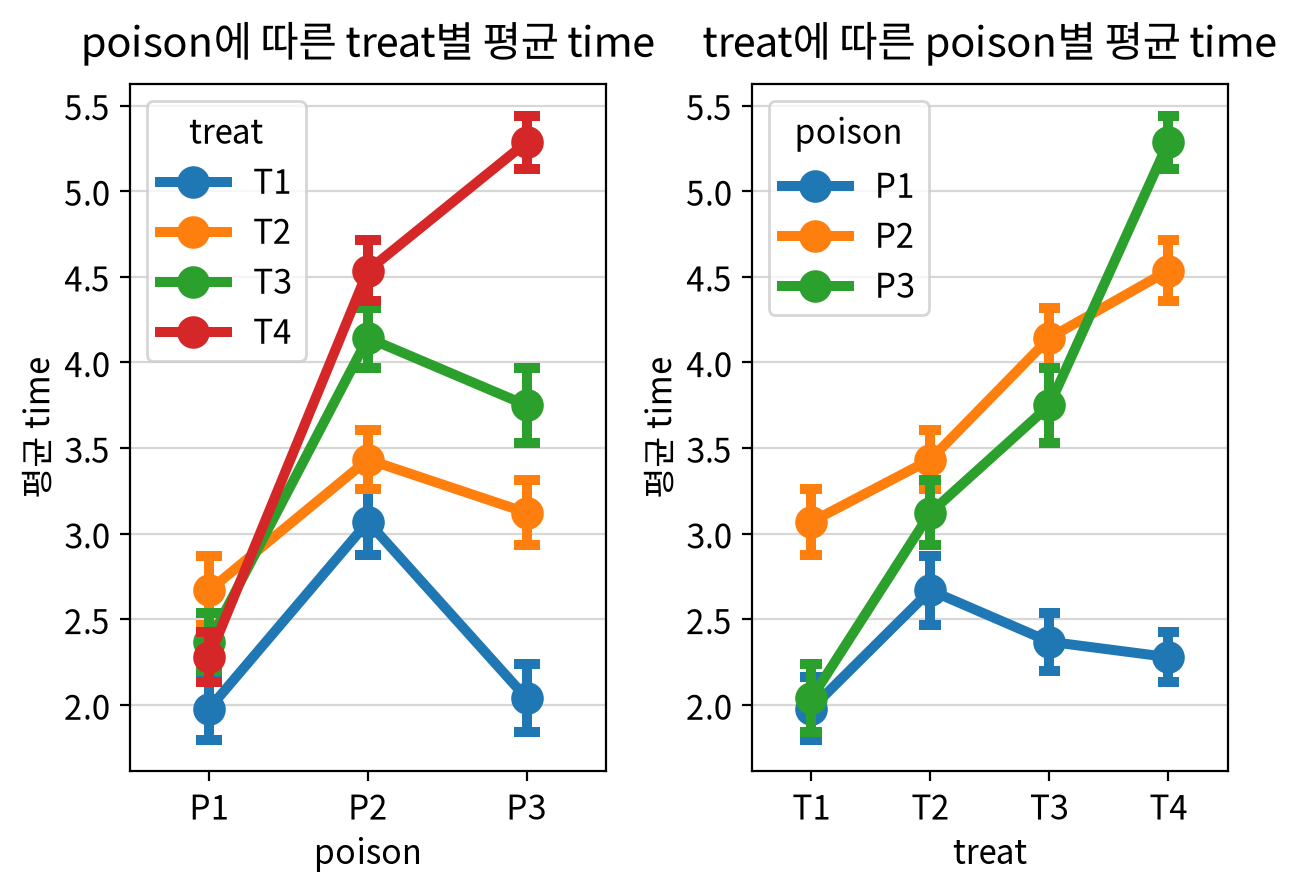

,test,Source,SS,DF,MS,F,p_unc,np2,significant,effect_size
0,two-way ANOVA,poison,148.976,2,74.488,74.722,0.000,0.300,True,Large
1,two-way ANOVA,treat,131.261,3,43.754,43.891,0.000,0.275,True,Large
2,two-way ANOVA,poison * treat,81.382,6,13.564,13.606,0.000,0.190,True,Large
3,two-way ANOVA,Residual,346.910,348,0.997,NaN,NaN,NaN,False,-


In [27]:
my_stats.anova_twoway(df2, y='time', between=['poison', 'treat'])

- poison의 주효과는 유의하다 (p < 0.05, np2=0.300).   
  - 독극물 종류에 따른 평균 생존시간 차이가 유의함.
- treat의 주효과도 유의하다 (p < 0.05, np2=0.275).    
  - 해독제 종류에 따른 평균 생존시간 차이가 유의함.
- 상호작용효과(poison * treat)는 유의하다 (p < 0.05).   
  - 해독제의 효과가 독극물 종류에 따라 유의하게 달라짐.
- 즉 상호작용이 유의하므로 해독제의 전체 평균만으로 최적 해독제를 선정하면 안 된다.

-  **답변**
1. 먼저 실험이 어떻게 짜여 있는지부터 확인해야 합니다. 두 요인의 수준을 모두 맞물린 처리 조합(셀)은 몇 개 인가요?
    - 12개
2. 두 요인과 그 맞물림까지 한 번에 검정했습니다. 유의수준 5% 기준으로, 세 효과 중 유의하다고 판정되는 효과는 몇 개인가요?
    - 3개
3. 생존시간의 변동을 가장 많이 설명하는 효과가 무엇인지 알아야 대응 우선순위를 정할 수 있습니다. 세 효과 중 효과크기(부분 에타제곱)가 가장 큰 효과는 무엇인가요?
    - poison
4. 상호작용이 유의했으므로 요인별 평균이 아니라 조합별 평균을 봐야 합니다. 평균 생존시간이 가장 긴 조합에 쓰인 해독제는 무엇인가요?
    - T4
5. 센터장은 4번의 결과만 보고 그 해독제를 표준으로 채택하려 합니다. 그런데 P1 독극물에 중독된 개체만 따로 떼어 보면, 평균 생존시간이 가장 긴 해독제는 무엇인가요?
    - T2